In [ ]:
# Instalación de librerias.
%pip install -q scikit-learn pandas numpy matplotlib scipy mlflow

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.2/50.2 kB 1.0 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 51.1/51.1 kB 2.2 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.3/44.3 kB 2.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 63.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.1/4.1 MB 60.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 60.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.7/268.7 kB 17.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 148.8/148.8 kB 10.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 114.9/114.9 kB 8.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 228.4/228.4 kB 15.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 136.5/136.5 kB 9.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 148.7/148.7 kB 10.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

In [ ]:
# Importación de librerias
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mlflow
import mlflow.sklearn
import os, json, hashlib, warnings
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_validate
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from pathlib import Path
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay
from scipy.stats import ttest_rel

Filas: 569 Variables: 30 Nulos: 0
Clases: 0=maligno, 1=benigno: {1: 357, 0: 212}


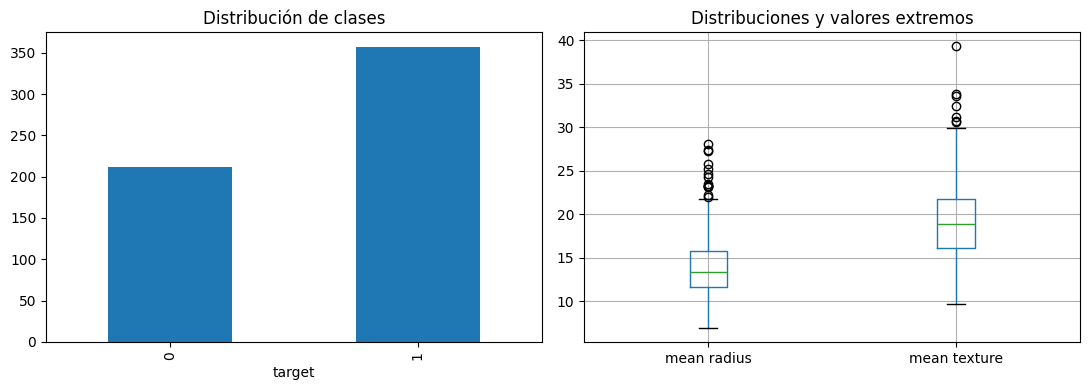

2026/10/18 03:54:23 INFO mlflow.tracking.fluent: Experiment with name 'Actividad5_BreastCancer' does not exist. Creating a new experiment.
2026/10/18 03:54:27 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/10/18 03:54:27 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


Regresion_logistica {'accuracy': 0.9824561403508771, 'precision': 0.9861111111111112, 'recall': 0.9861111111111112, 'f1': 0.9861111111111112, 'roc_auc': np.float64(0.9953703703703703)} {'modelo__C': 1}


2026/10/18 03:54:53 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/10/18 03:54:53 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


Random_forest {'accuracy': 0.956140350877193, 'precision': 0.958904109589041, 'recall': 0.9722222222222222, 'f1': 0.9655172413793104, 'roc_auc': np.float64(0.9933862433862434)} {'modelo__max_depth': 5, 'modelo__n_estimators': 100}


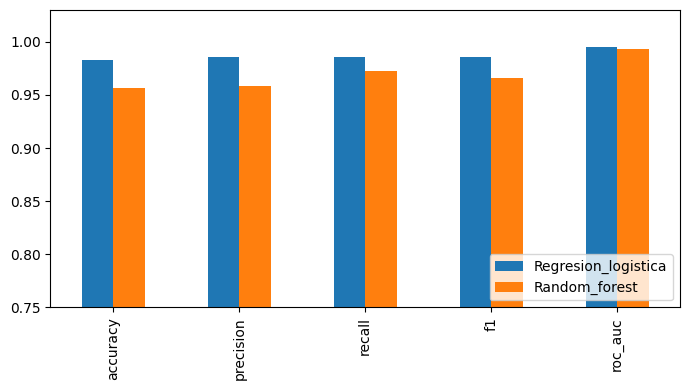

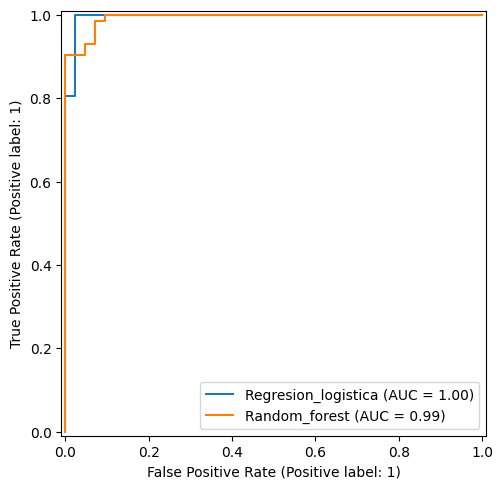

t pareada exploratoria: 1.618261303146891 p= 0.18091679148649115
MLflow: /content/mlruns


In [ ]:
#Función que carga el dataset y separa variables y etiquetas.
def obtener_datos():
    ds=load_breast_cancer(as_frame=True)
    X=ds.data.copy(); y=ds.target.copy()
    return X,y,ds

#Define la división estratificada y reproducible entre entrenamiento y prueba.
def dividir(X,y):
    return train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)

#Función para preprocesamiento de datos.
def preprocesador(escalar=False):
    pasos=[('imputar',SimpleImputer(strategy='median'))]
    if escalar: pasos.append(('escalar',StandardScaler()))
    return Pipeline(pasos)


# Identifica la carpeta de trabajo actual.
ROOT=Path.cwd()
# Corrige la ruta cuando el notebook se ejecuta desde fuentes/.
if not (ROOT/'fuentes').exists() and (ROOT.parent/'fuentes').exists(): ROOT=ROOT.parent
# Crea carpetas o guarda resultados según la ruta indicada.
(ROOT/'evidencias').mkdir(exist_ok=True)
(ROOT/'datos/datos_ini').mkdir(parents=True,exist_ok=True)
(ROOT/'datos/datos_limp').mkdir(parents=True,exist_ok=True)
#Carga del dataset.
X,y,ds=obtener_datos()
#Añade la etiqueta a una copia del dataset original.
raw=X.assign(target=y)
#Versiona los datos originales en CSV.
raw.to_csv(ROOT/'datos/datos_ini/breast_cancer_original.csv',index=False)
#Genera conjuntos de entrenamiento y prueba sin mezclar sus etiquetas.
X_train,X_test,y_train,y_test=dividir(X,y)
#Guarda el conjunto de entrenamiento ya preprocesado.
X_train.assign(target=y_train).to_csv(ROOT/'datos/datos_limp/train.csv',index=False)
# Guarda el conjunto de prueba ya preprocesado.
X_test.assign(target=y_test).to_csv(ROOT/'datos/datos_limp/test.csv',index=False)
print('Filas:',len(X),'Variables:',X.shape[1],'Nulos:',int(X.isna().sum().sum()))
print('Clases: 0=maligno, 1=benigno:',y.value_counts().to_dict())
fig,ax=plt.subplots(1,2,figsize=(11,4))
y.value_counts().sort_index().plot.bar(ax=ax[0],title='Distribución de clases')
X[['mean radius','mean texture']].boxplot(ax=ax[1]); ax[1].set_title('Distribuciones y valores extremos')
fig.tight_layout(); fig.savefig(ROOT/'evidencias/eda.png',dpi=160); plt.show()

# Permite el uso del almacenamiento local basado en archivos para MLflow
os.environ['MLFLOW_ALLOW_FILE_STORE'] = 'true'

# Configura el almacenamiento local de MLflow.
mlflow.set_tracking_uri((ROOT/'mlruns').resolve().as_uri())
# Selecciona el experimento que agrupa las ejecuciones.
mlflow.set_experiment('Actividad5_BreastCancer')
# Define validación cruzada estratificada de cinco particiones.
cv=StratifiedKFold(n_splits=5,shuffle=True,random_state=42)
# Declara los dos algoritmos y sus hiperparámetros.
configs={
 'Regresion_logistica':(LogisticRegression(max_iter=2000,random_state=42),True,{'modelo__C':[0.01,0.1,1,10]}),
 'Random_forest':(RandomForestClassifier(random_state=42,n_jobs=1),False,{'modelo__n_estimators':[100,200],'modelo__max_depth':[None,5,10]})
}
#Inicializa colecciones para resultados, AUC por fold y modelos ganadores.
results=[]; folds={}; best_models={}
#Recorre los algoritmos definidos.
for name,(est,scale,grid) in configs.items():
    #Encadena preparación y estimador para evitar fugas de datos.
    pipe=Pipeline([('preparacion',preprocesador(scale)),('modelo',est)])
    #Abre una ejecución de MLflow para este modelo.
    with mlflow.start_run(run_name=name):
        #Configura búsqueda de hiperparámetros con AUC como criterio.
        search=GridSearchCV(pipe,grid,cv=cv,scoring='roc_auc',n_jobs=1,refit=True)
        #Ajusta cada configuración solo con los datos de entrenamiento.
        search.fit(X_train,y_train)
        #Guarda el pipeline con los mejores hiperparámetros.
        best=search.best_estimator_; best_models[name]=best
        #Calcula métricas por fold del mejor pipeline.
        scores=cross_validate(best,X_train,y_train,cv=cv,scoring={'accuracy':'accuracy','precision':'precision','recall':'recall','f1':'f1','roc_auc':'roc_auc'},n_jobs=1)
        folds[name]=scores['test_roc_auc']
        #Obtiene probabilidades de clase positiva y predicciones.
        proba=best.predict_proba(X_test)[:,1]; pred=best.predict(X_test)
        #Calcula cinco métricas en el conjunto de prueba reservado.
        metrics={'accuracy':accuracy_score(y_test,pred),'precision':precision_score(y_test,pred),'recall':recall_score(y_test,pred),'f1':f1_score(y_test,pred),'roc_auc':roc_auc_score(y_test,proba)}
        #Registra hiperparámetros, semilla y detalles del dataset.
        mlflow.log_params({**search.best_params_,'dataset':'sklearn_breast_cancer','seed':42,'cv_folds':5,'test_fraction':0.2})
        #Registra métricas de validación cruzada y prueba.
        mlflow.log_metrics({'cv_roc_auc_best':search.best_score_,**{'cv_'+k+'_mean':float(np.mean(v)) for k,v in scores.items() if k.startswith('test_')},**{'test_'+k:v for k,v in metrics.items()}})
        #Dibuja la matriz de confusión.
        fig,ax=plt.subplots(figsize=(5,4)); ConfusionMatrixDisplay.from_predictions(y_test,pred,ax=ax); fig.tight_layout()
        cm_path=ROOT/f'evidencias/matriz_{name}.png';fig.savefig(cm_path,dpi=160);plt.close(fig)
        mlflow.log_artifact(str(cm_path),'figuras')
        mlflow.sklearn.log_model(best,artifact_path='modelo',serialization_format='cloudpickle')
        #Añade métricas y parámetros a la tabla comparativa.
        results.append({'modelo':name,**metrics,'cv_roc_auc':search.best_score_,'parametros':json.dumps(search.best_params_)})
        #Muestra el desempeño y los mejores parámetros del modelo.
        print(name,metrics,search.best_params_)
#Convierte los resultados a tabla y los exporta a CSV.
res=pd.DataFrame(results);res.to_csv(ROOT/'evidencias/metricas.csv',index=False)
fig,ax=plt.subplots(figsize=(7,4))
res.set_index('modelo')[['accuracy','precision','recall','f1','roc_auc']].T.plot.bar(ax=ax,ylim=(0.75,1.03));ax.legend(loc='lower right');fig.tight_layout();fig.savefig(ROOT/'evidencias/comparacion.png',dpi=160);plt.show()
fig,ax=plt.subplots(figsize=(6,5))
#Traza la curva ROC de cada modelo en el conjunto de prueba.
for name,model in best_models.items(): RocCurveDisplay.from_estimator(model,X_test,y_test,ax=ax,name=name)
fig.tight_layout();fig.savefig(ROOT/'evidencias/roc.png',dpi=160);plt.show()
a,b=folds.values();stat,pvalue=ttest_rel(a,b)
(ROOT/'evidencias/estadistica.json').write_text(json.dumps({'prueba':'t pareada exploratoria sobre AUC por fold','t':float(stat),'p_value':float(pvalue),'advertencia':'Los folds se reutilizan después de la selección de hiperparámetros; no es inferencia confirmatoria. Para inferencia robusta usar CV anidada.'},indent=2))
print('t pareada exploratoria:',stat,'p=',pvalue)
print('MLflow:',(ROOT/'mlruns').resolve())

In [ ]:
#Visualización de MLFlow
import subprocess
import time
from google.colab import output
from urllib.parse import urlparse
from IPython.display import display, HTML

# Obtener el dominio exacto del proxy de Colab
url = output.eval_js(
    "google.colab.kernel.proxyPort(5000)"
)

host_colab = urlparse(url).netloc

# Detener servidores MLflow anteriores de forma limpia
subprocess.run(
    ["pkill", "-f", "mlflow ui"],
    check=False
)
time.sleep(2)

# Iniciar MLflow escuchando en 0.0.0.0 y con comodines de CORS para evitar errores 500
log = open("/content/mlflow_server.log", "w")

servidor = subprocess.Popen(
    [
        "mlflow", "ui",
        "--backend-store-uri", "/content/mlruns",
        "--host", "0.0.0.0",
        "--port", "5000",
        "--allowed-hosts", "*",
        "--cors-allowed-origins", "*",
        "--x-frame-options", "NONE"
    ],
    stdout=log,
    stderr=subprocess.STDOUT
)

# Esperar un momento a que levante el proceso de fondo
time.sleep(4)

print("Servidor de MLflow inicializado con éxito de fondo.")

# Mostrar el enlace de acceso directo diseñado como botón interactivo
display(HTML(
    f'<a href="{url}" target="_blank" '
    'style="display: inline-block; padding: 12px 24px; background-color: #007bff; color: white; text-decoration: none; border-radius: 5px; font-weight: bold; font-family: sans-serif; box-shadow: 0 4px 6px rgba(0,0,0,0.1);" '
    'rel="noopener noreferrer">'
    'ABRIR PANEL DE MLFLOW</a>'
))

Servidor de MLflow inicializado con éxito de fondo.
